Stage 2: Downloading and loading the EuroSAT dataset.

Step 1. Import the libraries

In [4]:
import sys
import tensorflow as tf
import pyarrow
import datasets

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("PyArrow:", pyarrow.__version__)
print("Hugging Face:", datasets.__version__)

Python: c:\Users\hirwa\Documents\GeoVision-ML\.venv\Scripts\python.exe
TensorFlow: 2.21.0
PyArrow: 26.0.1
Hugging Face: 5.2.0


In [5]:
from datasets import load_dataset

eurosat = load_dataset("blanchon/EuroSAT_RGB")

print(eurosat)

README.md:   0%|          | 0.00/3.38k [00:00<?, ?B/s]

c:\Users\hirwa\Documents\GeoVision-ML\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\hirwa\.cache\huggingface\hub\datasets--blanchon--EuroSAT_RGB. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\hirwa\Documents\GeoVision-ML\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: Us

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  105MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 34.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/16200 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5400 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5400 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'filename'],
        num_rows: 16200
    })
    test: Dataset({
        features: ['image', 'label', 'filename'],
        num_rows: 5400
    })
    validation: Dataset({
        features: ['image', 'label', 'filename'],
        num_rows: 5400
    })
})


In [6]:
from datasets import load_dataset

# Download EuroSAT
eurosat = load_dataset("blanchon/EuroSAT_RGB")

print("Dataset downloaded successfully!")
print(eurosat)

Dataset downloaded successfully!
DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'filename'],
        num_rows: 16200
    })
    test: Dataset({
        features: ['image', 'label', 'filename'],
        num_rows: 5400
    })
    validation: Dataset({
        features: ['image', 'label', 'filename'],
        num_rows: 5400
    })
})


In [7]:
# Display available splits
print("Dataset splits:", eurosat.keys())

# Display number of images
for split in eurosat.keys():
    print(f"{split}: {len(eurosat[split])} images")

Dataset splits: dict_keys(['train', 'test', 'validation'])
train: 16200 images
test: 5400 images
validation: 5400 images


In [8]:
# Get the first image
sample = eurosat[list(eurosat.keys())[0]][0]

print("Available columns:", sample.keys())
print("Image dimensions:", sample["image"].size)
print("Image label:", sample["label"])

Available columns: dict_keys(['image', 'label', 'filename'])
Image dimensions: (64, 64)
Image label: 0


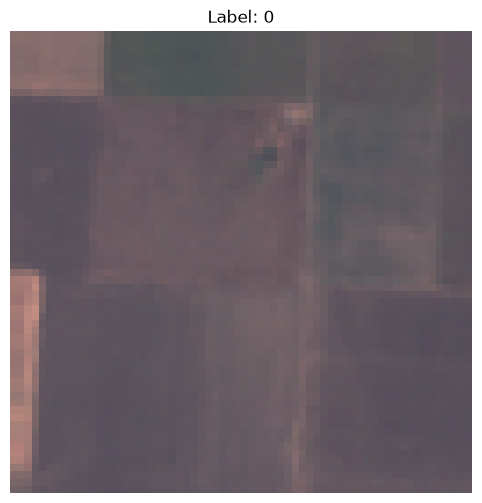

In [9]:
import matplotlib.pyplot as plt

sample = eurosat[list(eurosat.keys())[0]][0]

plt.figure(figsize=(6, 6))

plt.imshow(sample["image"])

plt.title(f"Label: {sample['label']}")

plt.axis("off")

plt.show()

In [10]:
class_names = eurosat[
    list(eurosat.keys())[0]
].features["label"].names

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

Number of classes: 10
0: Annual Crop
1: Forest
2: Herbaceous Vegetation
3: Highway
4: Industrial Buildings
5: Pasture
6: Permanent Crop
7: Residential Buildings
8: River
9: SeaLake


Stage 3 — Data Preprocessing.

Step 1. Import the preprocessing libraries

In [11]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from collections import Counter
from sklearn.model_selection import train_test_split

print("Preprocessing libraries imported successfully!")


Preprocessing libraries imported successfully!


Step 2. Inspect the dataset

In [12]:

# Display the available dataset splits
print("Dataset splits:", eurosat.keys())

# Select the original dataset split
source_data = eurosat["train"]

# Get class names
class_names = source_data.features["label"].names

print("\nTotal images:", len(source_data))
print("Number of classes:", len(class_names))

print("\nClass names:")
for i, name in enumerate(class_names):
    print(i, name)


Dataset splits: dict_keys(['train', 'test', 'validation'])

Total images: 16200
Number of classes: 10

Class names:
0 Annual Crop
1 Forest
2 Herbaceous Vegetation
3 Highway
4 Industrial Buildings
5 Pasture
6 Permanent Crop
7 Residential Buildings
8 River
9 SeaLake


Step 3. Divide the dataset into three groups

In [13]:

# First split: 80% training and 20% temporary data
train_test = source_data.train_test_split(
    test_size=0.20,
    seed=42,
    stratify_by_column="label"
)

train_data = train_test["train"]
temporary_data = train_test["test"]

# Second split: divide temporary data equally
validation_test = temporary_data.train_test_split(
    test_size=0.50,
    seed=42,
    stratify_by_column="label"
)

validation_data = validation_test["train"]
test_data = validation_test["test"]

# Display dataset sizes
print("Training images:", len(train_data))
print("Validation images:", len(validation_data))
print("Testing images:", len(test_data))

print("Total images:",
      len(train_data) + len(validation_data) + len(test_data))


Training images: 12960
Validation images: 1620
Testing images: 1620
Total images: 16200


Step 4. Check the distribution of classes

In [14]:

def get_class_distribution(dataset):
    counts = Counter(dataset["label"])

    return pd.DataFrame({
        "Category": class_names,
        "Number_of_Images": [
            counts.get(i, 0) for i in range(len(class_names))
        ]
    })

train_distribution = get_class_distribution(train_data)
validation_distribution = get_class_distribution(validation_data)
test_distribution = get_class_distribution(test_data)

print("Training distribution:")
print(train_distribution)


Training distribution:
                Category  Number_of_Images
0            Annual Crop              1433
1                 Forest              1429
2  Herbaceous Vegetation              1439
3                Highway              1204
4   Industrial Buildings              1194
5                Pasture               956
6         Permanent Crop              1185
7  Residential Buildings              1490
8                  River              1168
9                SeaLake              1462


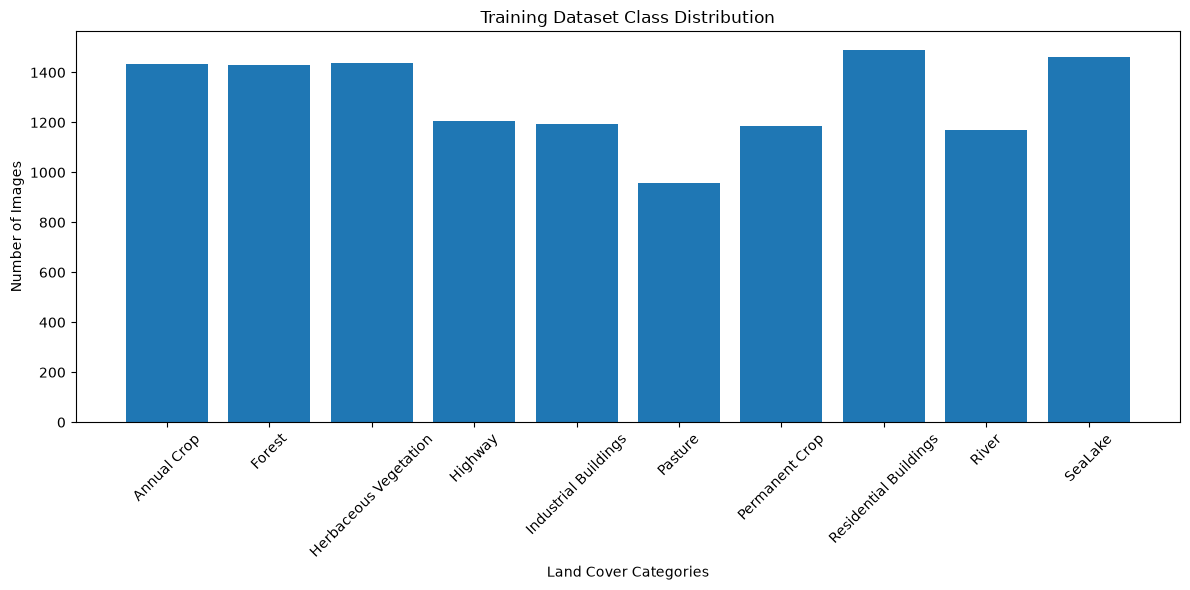

In [15]:

plt.figure(figsize=(12, 6))

plt.bar(
    train_distribution["Category"],
    train_distribution["Number_of_Images"]
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Land Cover Categories")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


Step 5. Check for missing or invalid images

In [16]:

def check_dataset(dataset):
    invalid_images = 0
    missing_labels = 0

    for example in dataset:
        image = example["image"]
        label = example["label"]

        if image is None:
            invalid_images += 1
            continue

        if label is None:
            missing_labels += 1

        if image.mode != "RGB":
            image = image.convert("RGB")

    return invalid_images, missing_labels


invalid_train, missing_train = check_dataset(train_data)

print("Invalid images:", invalid_train)
print("Missing labels:", missing_train)


Invalid images: 0
Missing labels: 0


In [17]:
invalid_val, missing_val = check_dataset(validation_data)
invalid_test, missing_test = check_dataset(test_data)

print("Validation invalid images:", invalid_val)
print("Validation missing labels:", missing_val)

print("Testing invalid images:", invalid_test)
print("Testing missing labels:", missing_test)

Validation invalid images: 0
Validation missing labels: 0
Testing invalid images: 0
Testing missing labels: 0


Step 6. Resize and normalize the images

In [18]:

IMG_SIZE = 64

def preprocess_image(image):
    # Convert image to RGB
    image = image.convert("RGB")

    # Convert PIL image to NumPy array
    image = np.array(image, dtype=np.float32)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Normalize pixel values
    image = image / 255.0

    return image


In [19]:

sample = train_data[0]

original_image = sample["image"]
processed_image = preprocess_image(original_image)

print("Original image size:", original_image.size)
print("Processed image shape:", processed_image.shape)

print("Minimum pixel value:",
      tf.reduce_min(processed_image).numpy())

print("Maximum pixel value:",
      tf.reduce_max(processed_image).numpy())


Original image size: (64, 64)
Processed image shape: (64, 64, 3)
Minimum pixel value: 0.12156863
Maximum pixel value: 0.5568628


Step 7. Create TensorFlow datasets

In [20]:

def create_tf_dataset(dataset, batch_size=32, training=False):

    def generator():
        for example in dataset:
            image = preprocess_image(example["image"])
            label = np.int32(example["label"])

            yield image.numpy(), label

    output_signature = (
        tf.TensorSpec(
            shape=(IMG_SIZE, IMG_SIZE, 3),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(),
            dtype=tf.int32
        )
    )

    tf_dataset = tf.data.Dataset.from_generator(
        generator,
        output_signature=output_signature
    )

    if training:
        tf_dataset = tf_dataset.shuffle(
            buffer_size=2000,
            seed=42
        )

    tf_dataset = tf_dataset.batch(batch_size)

    tf_dataset = tf_dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return tf_dataset


In [21]:

BATCH_SIZE = 32

train_ds = create_tf_dataset(
    train_data,
    batch_size=BATCH_SIZE,
    training=True
)

validation_ds = create_tf_dataset(
    validation_data,
    batch_size=BATCH_SIZE
)

test_ds = create_tf_dataset(
    test_data,
    batch_size=BATCH_SIZE
)

print("TensorFlow datasets created successfully!")


TensorFlow datasets created successfully!


Step 8. Apply data augmentation

In [22]:

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

print("Data augmentation pipeline created!")


Data augmentation pipeline created!


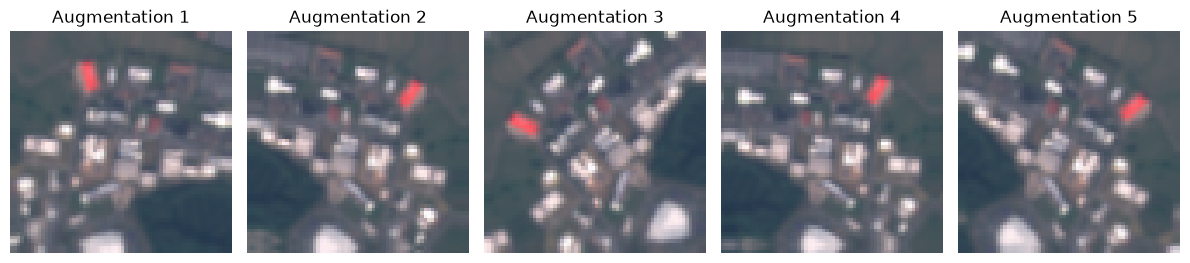

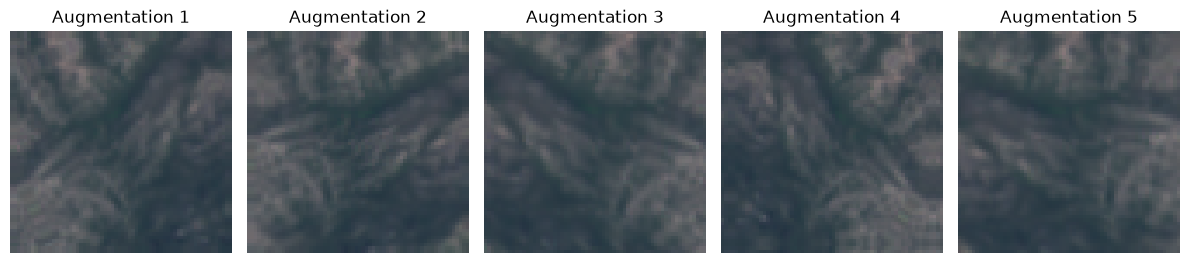

In [23]:

# Get one training image
sample_image, sample_label = next(iter(train_ds))

# Select the first image
image = sample_image[0]

plt.figure(figsize=(12, 6))

for i in range(5):
    augmented_image = data_augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )

    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented_image[0].numpy())
    plt.title(f"Augmentation {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

# Get one training image
sample_image, sample_label = next(iter(train_ds))

# Select the first image
image = sample_image[0]

plt.figure(figsize=(12, 6))

for i in range(5):
    augmented_image = data_augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )

    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented_image[0].numpy())
    plt.title(f"Augmentation {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Step 9. Verify our final preprocessing pipeline

In [24]:

# Get one batch from training data
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

print("Number of images in batch:", images.shape[0])


Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int32'>
Minimum pixel value: 0.07058824
Maximum pixel value: 1.0
Number of images in batch: 32


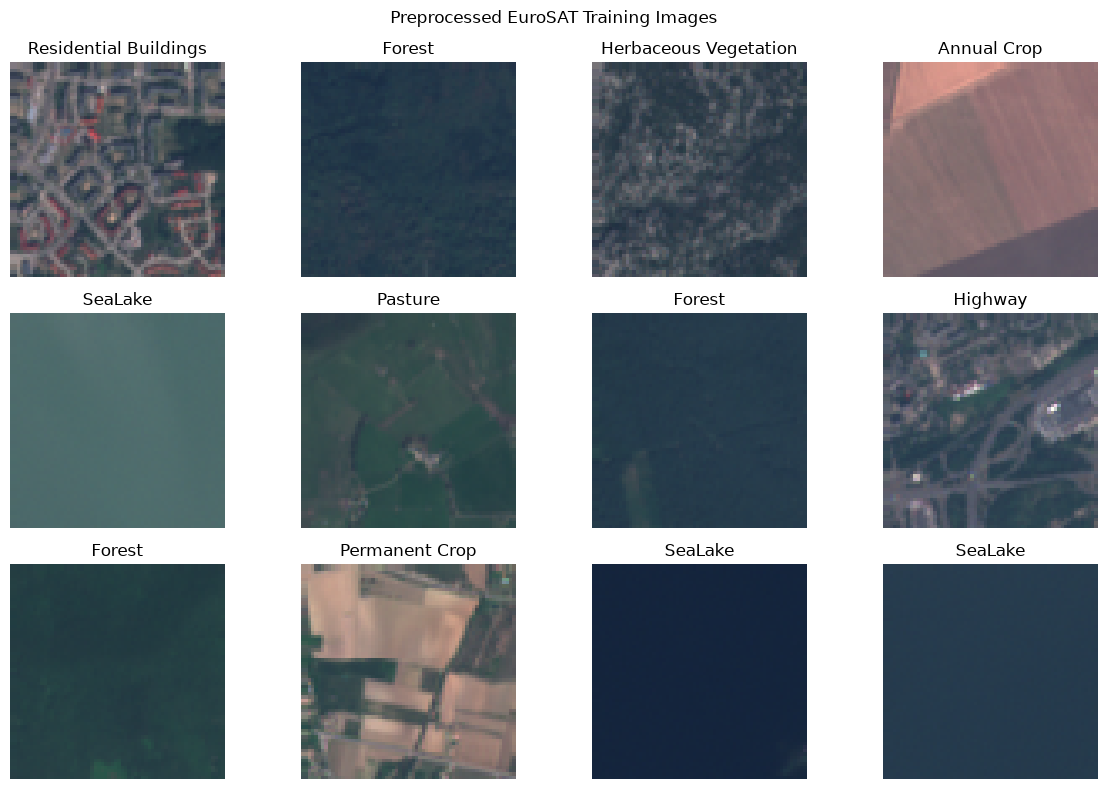

In [25]:

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(images[i].numpy())

    label_index = labels[i].numpy()

    plt.title(class_names[label_index])

    plt.axis("off")

plt.suptitle("Preprocessed EuroSAT Training Images")

plt.tight_layout()
plt.show()


Stage 4 — Model Creation and Training for GeoVision ML.

Step 1. Import libraries

In [26]:

import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import time

print("Model development libraries ready!")


Model development libraries ready!


Step 2. Build the CNN model

In [27]:

cnn_model = models.Sequential([

    # Input layer
    layers.Input(shape=(64, 64, 3)),

    # Data augmentation
    data_augmentation,

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    # Output layer
    layers.Dense(len(class_names), activation="softmax")
])

print("CNN model created!")


CNN model created!


Step 3. Understand the architecture

In [28]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,143,242 (4.36 MB)

 Trainable params: 1,143,242 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

Step 4. Compile the model

In [29]:

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("CNN compiled successfully!")


CNN compiled successfully!


Step 5. Train the CNN

In [30]:

start_time = time.time()

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=15
)

cnn_training_time = time.time() - start_time

print("CNN training completed!")
print("Training time:", round(cnn_training_time, 2), "seconds")


Epoch 1/15


c:\Users\hirwa\Documents\GeoVision-ML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


    405/Unknown 67s 148ms/step - accuracy: 0.3506 - loss: 1.6869

c:\Users\hirwa\Documents\GeoVision-ML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


405/405 ━━━━━━━━━━━━━━━━━━━━ 75s 167ms/step - accuracy: 0.3506 - loss: 1.6869 - val_accuracy: 0.4426 - val_loss: 1.5371
Epoch 2/15
405/405 ━━━━━━━━━━━━━━━━━━━━ 62s 144ms/step - accuracy: 0.5512 - loss: 1.2573 - val_accuracy: 0.6074 - val_loss: 1.1049
Epoch 3/15
405/405 ━━━━━━━━━━━━━━━━━━━━ 65s 151ms/step - accuracy: 0.6150 - loss: 1.0743 - val_accuracy: 0.6463 - val_loss: 1.0053
Epoch 4/15
405/405 ━━━━━━━━━━━━━━━━━━━━ 55s 128ms/step - accuracy: 0.6559 - loss: 0.9679 - val_accuracy: 0.6562 - val_loss: 1.0713
Epoch 5/15
405/405 ━━━━━━━━━━━━━━━━━━━━ 77s 180ms/step - accuracy: 0.6780 - loss: 0.8927 - val_accuracy: 0.7272 - val_loss: 0.7546
Epoch 6/15
405/405 ━━━━━━━━━━━━━━━━━━━━ 91s 214ms/step - accuracy: 0.6953 - loss: 0.8564 - val_accuracy: 0.6556 - val_loss: 1.0528
Epoch 7/15
405/405 ━━━━━━━━━━━━━━━━━━━━ 68s 145ms/step - accuracy: 0.7207 - loss: 0.7915 - val_accuracy: 0.6858 - val_loss: 0.9088
Epoch 8/15
405/405 ━━━━━━━━━━━━━━━━━━━━ 52s 117ms/step - accuracy: 0.7276 - loss: 0.7682 - val

Step 6. Visualize training performance

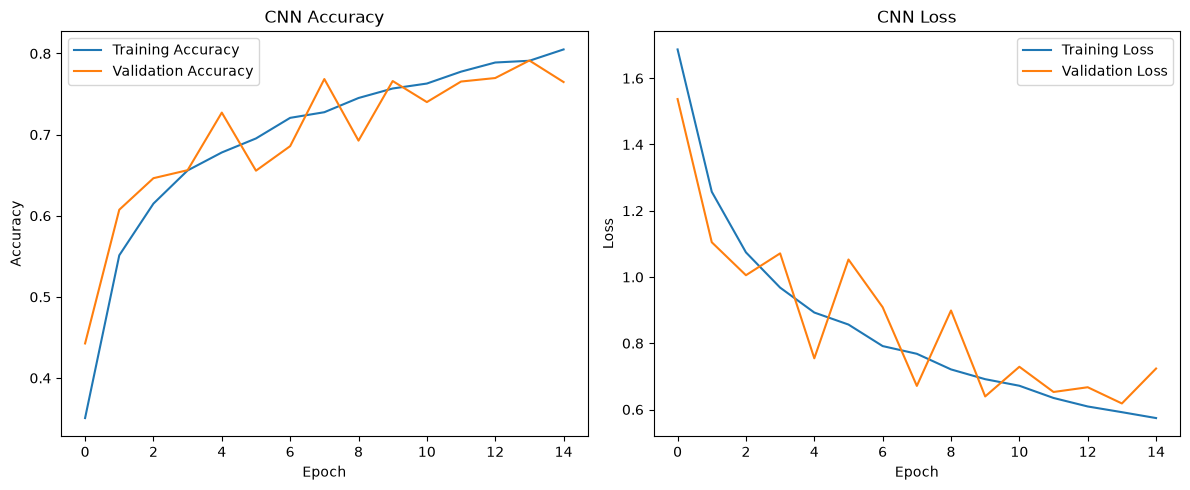

In [31]:

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)

plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


2. Model 2 — MobileNetV2

Step 1. Create a MobileNetV2 preprocessing pipeline

In [32]:

def prepare_mobilenet(image, label):
    image = tf.image.resize(image, [96, 96])

    # Convert values from [0, 1] to [-1, 1]
    image = image * 2.0 - 1.0

    return image, label


mobile_train_ds = train_ds.map(prepare_mobilenet)
mobile_validation_ds = validation_ds.map(prepare_mobilenet)
mobile_test_ds = test_ds.map(prepare_mobilenet)


Step 2. Load MobileNetV2

In [33]:

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
MobileNetV2 loaded successfully!


Step 3. Build the classification model

In [34]:

inputs = tf.keras.Input(shape=(96, 96, 3))

# Apply augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)

# Extract image features
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

mobilenet_model = tf.keras.Model(inputs, outputs)

print("MobileNetV2 classification model created!")


MobileNetV2 classification model created!


Step 4. Compile MobileNetV2

In [35]:

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Step 5. Train MobileNetV2

In [36]:

start_time = time.time()

mobilenet_history = mobilenet_model.fit(
    mobile_train_ds,
    validation_data=mobile_validation_ds,
    epochs=10
)

mobilenet_training_time = time.time() - start_time

print("MobileNetV2 training completed!")
print("Training time:", round(mobilenet_training_time, 2), "seconds")


Epoch 1/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 78s 166ms/step - accuracy: 0.7925 - loss: 0.6191 - val_accuracy: 0.8815 - val_loss: 0.3422
Epoch 2/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 85s 185ms/step - accuracy: 0.8806 - loss: 0.3427 - val_accuracy: 0.9086 - val_loss: 0.2794
Epoch 3/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 70s 166ms/step - accuracy: 0.8972 - loss: 0.2944 - val_accuracy: 0.9130 - val_loss: 0.2677
Epoch 4/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 82s 189ms/step - accuracy: 0.8986 - loss: 0.2912 - val_accuracy: 0.9105 - val_loss: 0.2564
Epoch 5/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 86s 203ms/step - accuracy: 0.9045 - loss: 0.2728 - val_accuracy: 0.9179 - val_loss: 0.2527
Epoch 6/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 87s 198ms/step - accuracy: 0.9047 - loss: 0.2659 - val_accuracy: 0.9191 - val_loss: 0.2413
Epoch 7/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 85s 188ms/step - accuracy: 0.9100 - loss: 0.2605 - val_accuracy: 0.9136 - val_loss: 0.2652
Epoch 8/10
405/405 ━━━━━━━━━━━━━━━━━━━━ 90s 214ms/step - accuracy: 0.9113 - loss: 0

4. Save both trained models

In [37]:

import os

os.makedirs("../models", exist_ok=True)

cnn_model.save("../models/geovision_cnn.keras")

mobilenet_model.save("../models/geovision_mobilenet.keras")

print("Both models saved successfully!")


Both models saved successfully!


Stage 5 — Model Evaluation and Comparison for GeoVision ML.

1. Prepare the evaluation environment

In [38]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize

print("Evaluation libraries imported successfully!")


Evaluation libraries imported successfully!


2. Evaluate the Custom CNN

In [39]:

# Get actual labels from the testing dataset
y_test = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Generate predictions
cnn_probabilities = cnn_model.predict(test_ds)

# Convert probabilities into predicted classes
cnn_predictions = np.argmax(cnn_probabilities, axis=1)

print("CNN predictions generated!")
print("Actual labels:", y_test.shape)
print("Predictions:", cnn_predictions.shape)


51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step
CNN predictions generated!
Actual labels: (1620,)
Predictions: (1620,)


3. Calculate CNN evaluation metrics

In [40]:

cnn_accuracy = accuracy_score(
    y_test,
    cnn_predictions
)

cnn_precision = precision_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

cnn_recall = recall_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

cnn_f1 = f1_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

print("CUSTOM CNN EVALUATION")
print("---------------------")

print("Accuracy:", round(cnn_accuracy, 4))
print("Precision:", round(cnn_precision, 4))
print("Recall:", round(cnn_recall, 4))
print("F1-score:", round(cnn_f1, 4))


CUSTOM CNN EVALUATION
---------------------
Accuracy: 0.7858
Precision: 0.8051
Recall: 0.7858
F1-score: 0.7831


4. Generate the CNN classification report

In [43]:

cnn_report = classification_report(
    y_test,
    cnn_predictions,
    target_names=class_names,
    zero_division=0
)

print(cnn_report)


                       precision    recall  f1-score   support

          Annual Crop       0.91      0.85      0.88       179
               Forest       0.86      0.96      0.91       179
Herbaceous Vegetation       0.82      0.64      0.72       180
              Highway       0.58      0.61      0.59       150
 Industrial Buildings       0.84      0.92      0.88       149
              Pasture       0.84      0.77      0.80       120
       Permanent Crop       0.78      0.47      0.59       148
Residential Buildings       0.59      0.99      0.74       187
                River       0.84      0.66      0.74       146
              SeaLake       0.98      0.88      0.93       182

             accuracy                           0.79      1620
            macro avg       0.80      0.78      0.78      1620
         weighted avg       0.81      0.79      0.78      1620



5. Visualize the CNN confusion matrix

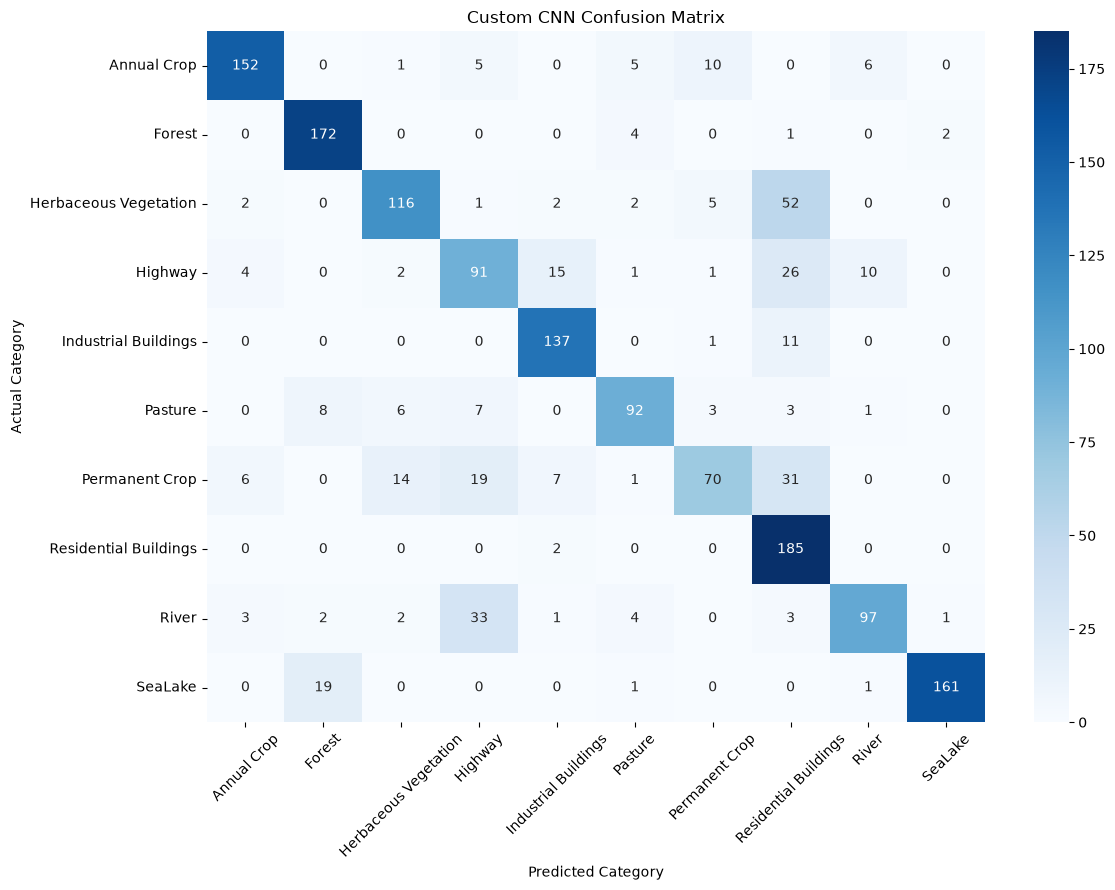

In [44]:

cnn_cm = confusion_matrix(
    y_test,
    cnn_predictions
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


6. Evaluate MobileNetV2

In [45]:

# Generate MobileNetV2 predictions
mobilenet_probabilities = mobilenet_model.predict(
    mobile_test_ds
)

mobilenet_predictions = np.argmax(
    mobilenet_probabilities,
    axis=1
)

print("MobileNetV2 predictions generated!")


51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step
MobileNetV2 predictions generated!


c:\Users\hirwa\Documents\GeoVision-ML\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [46]:

mobilenet_accuracy = accuracy_score(
    y_test,
    mobilenet_predictions
)

mobilenet_precision = precision_score(
    y_test,
    mobilenet_predictions,
    average="weighted",
    zero_division=0
)

mobilenet_recall = recall_score(
    y_test,
    mobilenet_predictions,
    average="weighted",
    zero_division=0
)

mobilenet_f1 = f1_score(
    y_test,
    mobilenet_predictions,
    average="weighted",
    zero_division=0
)

print("MOBILENETV2 EVALUATION")
print("----------------------")

print("Accuracy:", round(mobilenet_accuracy, 4))
print("Precision:", round(mobilenet_precision, 4))
print("Recall:", round(mobilenet_recall, 4))
print("F1-score:", round(mobilenet_f1, 4))


MOBILENETV2 EVALUATION
----------------------
Accuracy: 0.9296
Precision: 0.9305
Recall: 0.9296
F1-score: 0.9297


In [47]:

print(classification_report(
    y_test,
    mobilenet_predictions,
    target_names=class_names,
    zero_division=0
))


                       precision    recall  f1-score   support

          Annual Crop       0.89      0.95      0.92       179
               Forest       0.97      0.97      0.97       179
Herbaceous Vegetation       0.91      0.89      0.90       180
              Highway       0.94      0.87      0.90       150
 Industrial Buildings       0.96      0.95      0.96       149
              Pasture       0.89      0.85      0.87       120
       Permanent Crop       0.88      0.92      0.90       148
Residential Buildings       0.98      0.99      0.99       187
                River       0.85      0.88      0.87       146
              SeaLake       0.99      0.97      0.98       182

             accuracy                           0.93      1620
            macro avg       0.93      0.93      0.93      1620
         weighted avg       0.93      0.93      0.93      1620



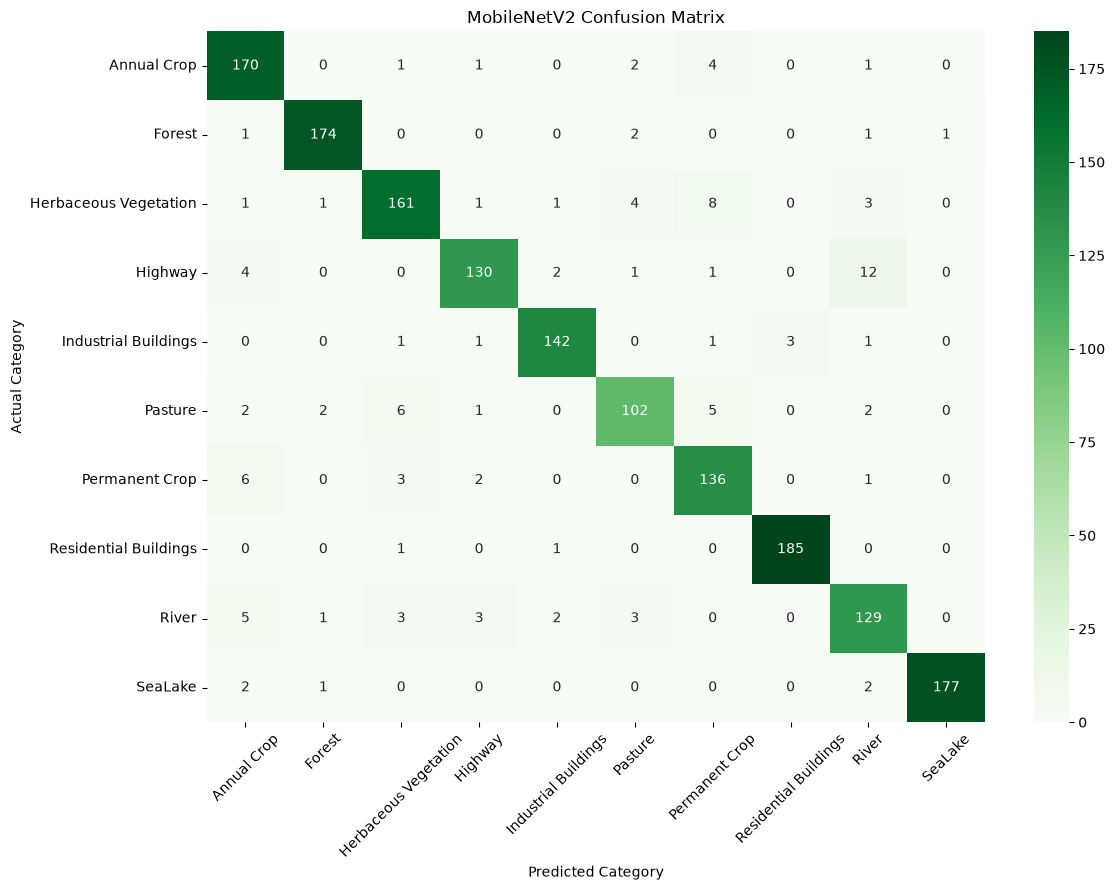

In [48]:

mobilenet_cm = confusion_matrix(
    y_test,
    mobilenet_predictions
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


7. Calculate ROC-AUC for both models

In [49]:

# Convert labels into one-hot encoded format
y_test_binary = label_binarize(
    y_test,
    classes=np.arange(len(class_names))
)

# Calculate multiclass ROC-AUC
cnn_auc = roc_auc_score(
    y_test_binary,
    cnn_probabilities,
    average="macro",
    multi_class="ovr"
)

mobilenet_auc = roc_auc_score(
    y_test_binary,
    mobilenet_probabilities,
    average="macro",
    multi_class="ovr"
)

print("CNN ROC-AUC:", round(cnn_auc, 4))
print("MobileNetV2 ROC-AUC:", round(mobilenet_auc, 4))


CNN ROC-AUC: 0.9729
MobileNetV2 ROC-AUC: 0.996


8. Compare the two models

In [50]:

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Training Time (seconds)"
    ],

    "Custom CNN": [
        cnn_accuracy,
        cnn_precision,
        cnn_recall,
        cnn_f1,
        cnn_auc,
        cnn_training_time
    ],

    "MobileNetV2": [
        mobilenet_accuracy,
        mobilenet_precision,
        mobilenet_recall,
        mobilenet_f1,
        mobilenet_auc,
        mobilenet_training_time
    ]
})

print(comparison.to_string(index=False))


                 Metric  Custom CNN  MobileNetV2
               Accuracy    0.785802     0.929630
              Precision    0.805139     0.930465
                 Recall    0.785802     0.929630
               F1-score    0.783130     0.929674
                ROC-AUC    0.972903     0.996017
Training Time (seconds)  910.295771   836.921920


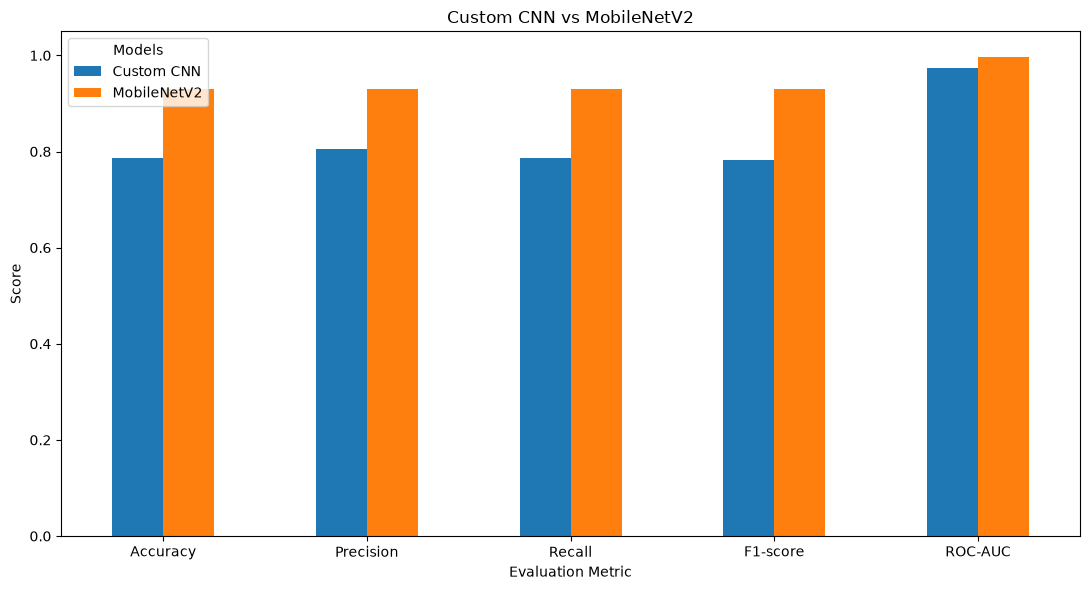

In [51]:

metrics_comparison = comparison[
    comparison["Metric"] != "Training Time (seconds)"
]

metrics_comparison = metrics_comparison.set_index("Metric")

metrics_comparison.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Custom CNN vs MobileNetV2")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")

plt.xticks(rotation=0)
plt.ylim(0, 1.05)

plt.legend(title="Models")
plt.tight_layout()
plt.show()


9. Select the best-performing model

In [52]:

if mobilenet_f1 > cnn_f1:
    best_model = mobilenet_model
    best_model_name = "MobileNetV2"
    best_probabilities = mobilenet_probabilities

elif cnn_f1 > mobilenet_f1:
    best_model = cnn_model
    best_model_name = "Custom CNN"
    best_probabilities = cnn_probabilities

else:
    best_model = (
        mobilenet_model
        if mobilenet_training_time < cnn_training_time
        else cnn_model
    )

    best_model_name = (
        "MobileNetV2"
        if best_model is mobilenet_model
        else "Custom CNN"
    )

    best_probabilities = (
        mobilenet_probabilities
        if best_model is mobilenet_model
        else cnn_probabilities
    )

print("Selected model:", best_model_name)


Selected model: MobileNetV2


10. Save the evaluation results

In [53]:

import os

os.makedirs("../results", exist_ok=True)

comparison.to_csv(
    "../results/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")


Model comparison saved successfully!


In [54]:

np.save(
    "../results/cnn_confusion_matrix.npy",
    cnn_cm
)

np.save(
    "../results/mobilenet_confusion_matrix.npy",
    mobilenet_cm
)

print("Confusion matrices saved!")


Confusion matrices saved!


Stage 6: Building the Prediction System.

Save the model metadata

In [55]:

import os
import json

# Create models directory if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the class names and model configuration
metadata = {
    "project": "GeoVision ML",
    "image_classes": class_names,
    "number_of_classes": len(class_names),
    "cnn_image_size": 64,
    "mobilenet_image_size": 96,
    "models": [
        "cnn",
        "mobilenet"
    ]
}

with open("../models/metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Model metadata saved successfully!")


Model metadata saved successfully!


Step 1. Import the prediction functions

In [56]:

import sys

# Add project root to Python path
sys.path.insert(0, "../")

from src.prediction import (
    load_prediction_model,
    predict_image
)

from PIL import Image

print("Prediction module imported successfully!")


Prediction module imported successfully!


Step 2. Load your trained model

In [57]:

model_name = "mobilenet"

model = load_prediction_model(model_name)

print("Model loaded successfully!")


Model loaded successfully!


In [58]:
model_name = "cnn"
model = load_prediction_model(model_name)

Step 3. Select an image for prediction

Actual category: SeaLake


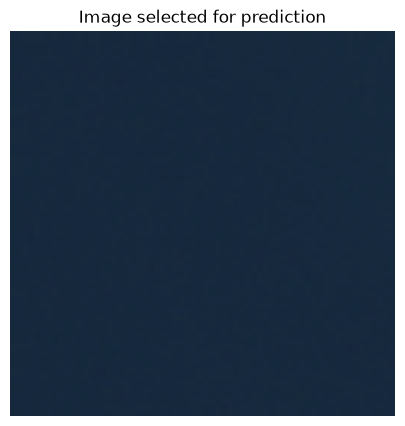

In [59]:

# Select an image from the test dataset
sample = test_data[0]

uploaded_image = sample["image"]

actual_label = sample["label"]

print("Actual category:", class_names[actual_label])

plt.figure(figsize=(5, 5))
plt.imshow(uploaded_image)
plt.title("Image selected for prediction")
plt.axis("off")
plt.show()


Step 4. Generate a prediction

In [61]:

result = predict_image(
    image=uploaded_image,
    model=model,
    model_name=model_name,
    class_names=class_names
)

print("PREDICTION RESULT")
print("-----------------")

print("Predicted category:",
      result["predicted_class"])

print("Confidence:",
      f"{result['confidence'] * 100:.2f}%")

print("Actual category:",
      class_names[actual_label])


PREDICTION RESULT
-----------------
Predicted category: SeaLake
Confidence: 99.87%
Actual category: SeaLake


Step 5. Visualize the prediction probabilities

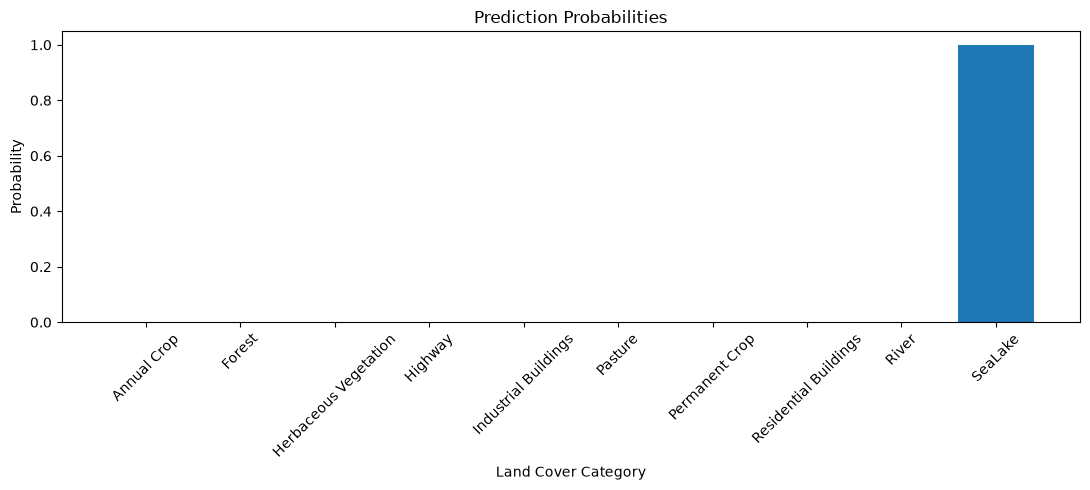

In [62]:

probabilities = result["probabilities"]

plt.figure(figsize=(11, 5))

plt.bar(
    probabilities.keys(),
    probabilities.values()
)

plt.title("Prediction Probabilities")
plt.xlabel("Land Cover Category")
plt.ylabel("Probability")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


6. Test the prediction system with both models

In [63]:

# CNN prediction
cnn_model_loaded = load_prediction_model("cnn")

cnn_result = predict_image(
    uploaded_image,
    cnn_model_loaded,
    "cnn",
    class_names
)

# MobileNetV2 prediction
mobilenet_model_loaded = load_prediction_model("mobilenet")

mobilenet_result = predict_image(
    uploaded_image,
    mobilenet_model_loaded,
    "mobilenet",
    class_names
)

print("CNN prediction:",
      cnn_result["predicted_class"])

print("CNN confidence:",
      round(cnn_result["confidence"] * 100, 2), "%")

print("\nMobileNetV2 prediction:",
      mobilenet_result["predicted_class"])

print("MobileNetV2 confidence:",
      round(mobilenet_result["confidence"] * 100, 2), "%")


CNN prediction: SeaLake
CNN confidence: 99.87 %

MobileNetV2 prediction: SeaLake
MobileNetV2 confidence: 100.0 %
